# 1. Question

Journeys are derived, not given: no journey_id exists in the raw data. Rule variants were scored against the hidden intents to test recovery and abandonment dynamics. This report analyzes what customers do after a payment fails, and where recovery is lost.

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

rep_dir = os.path.abspath(os.path.join(os.getcwd(), 'reports')) if os.path.exists('reports') else os.path.abspath(os.path.join(os.getcwd(), '..', 'reports'))
print('Reports directory:', rep_dir)

Reports directory: D:\Analyst\PaymentIQ\reports


# 2. Journey rules and window sensitivity

Four rules were tested: 15, 30, and 60 minutes, and w30b (30 minutes plus a new journey after any success). w30b is the recommended definition: it cuts merging by 93 percent against w30 using domain logic (a retry follows a failure). Recovery on eligible journeys is 33.26 percent in truth and 32.41 percent under w30b.

In [2]:
with open(os.path.join(rep_dir, 'phase5_1_checks_output.txt'), 'r', encoding='utf-8') as f:
    text = f.read()
for section in text.split('=== CHECK: '):
    if '04 recovery metrics' in section:
        print('=== CHECK: ' + section.strip())

=== CHECK: 04 recovery metrics per variant against the truth (metric dictionary definitions) ===
-- CHECK: 04 recovery metrics per variant against the truth (metric dictionary definitions)
-- EXPECT: truth row recovery_pct about 33.3 and recovery_all_pct about 31.7; derived rows within a few points; retry_rate_pct about 44 to 46 in truth
variant  journeys first_attempt_success_pct  failed_first retry_rate_pct  eligible recovery_pct abandonment_pct recovery_all_pct
  truth    280000                     90.38         25592          44.91     24395        33.26           66.74            31.73
    w15    278579                     90.30         25659          42.96     24470        31.69           68.31            30.29
    w30    275508                     90.31         25370          43.52     24192        32.29           67.71            30.90
   w30b    280336                     90.31         25805          43.62     24610        32.41           67.59            31.02
    w60    2721

# 3. Retry timing and the recovery funnel

Median wait before a retry is about 41 seconds, with about 5 percent of retries coming after more than 30 minutes. Of 24,610 eligible failed journeys under w30b, 45.45 percent were retried and 32.41 percent recovered. Crucially, 80.7 percent of unrecovered journeys were never retried.

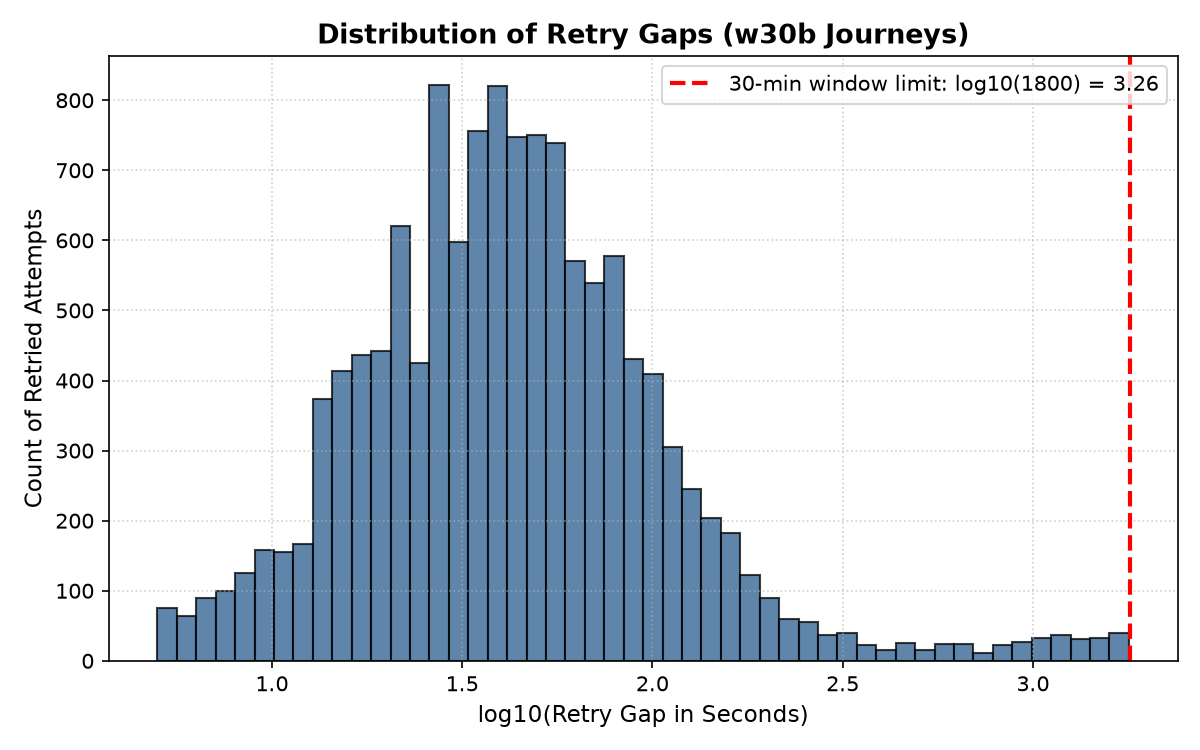

In [3]:
display(Image(filename=os.path.join(rep_dir, 'figures', 'p5_retry_gap.png')))

# 4. Segments

Behavioural segments are real at group level: retry rate by true segment is 0.27 (Abandoning), 0.43 (Reliable), 0.54 (Retry-dependent), and High-value amounts are about 2.5 times larger. However, they are not recoverable at customer level (rules agree with hidden labels 46.2 percent of the time, adjusted Rand index 0.064) because customers have only about 0.7 failures each.

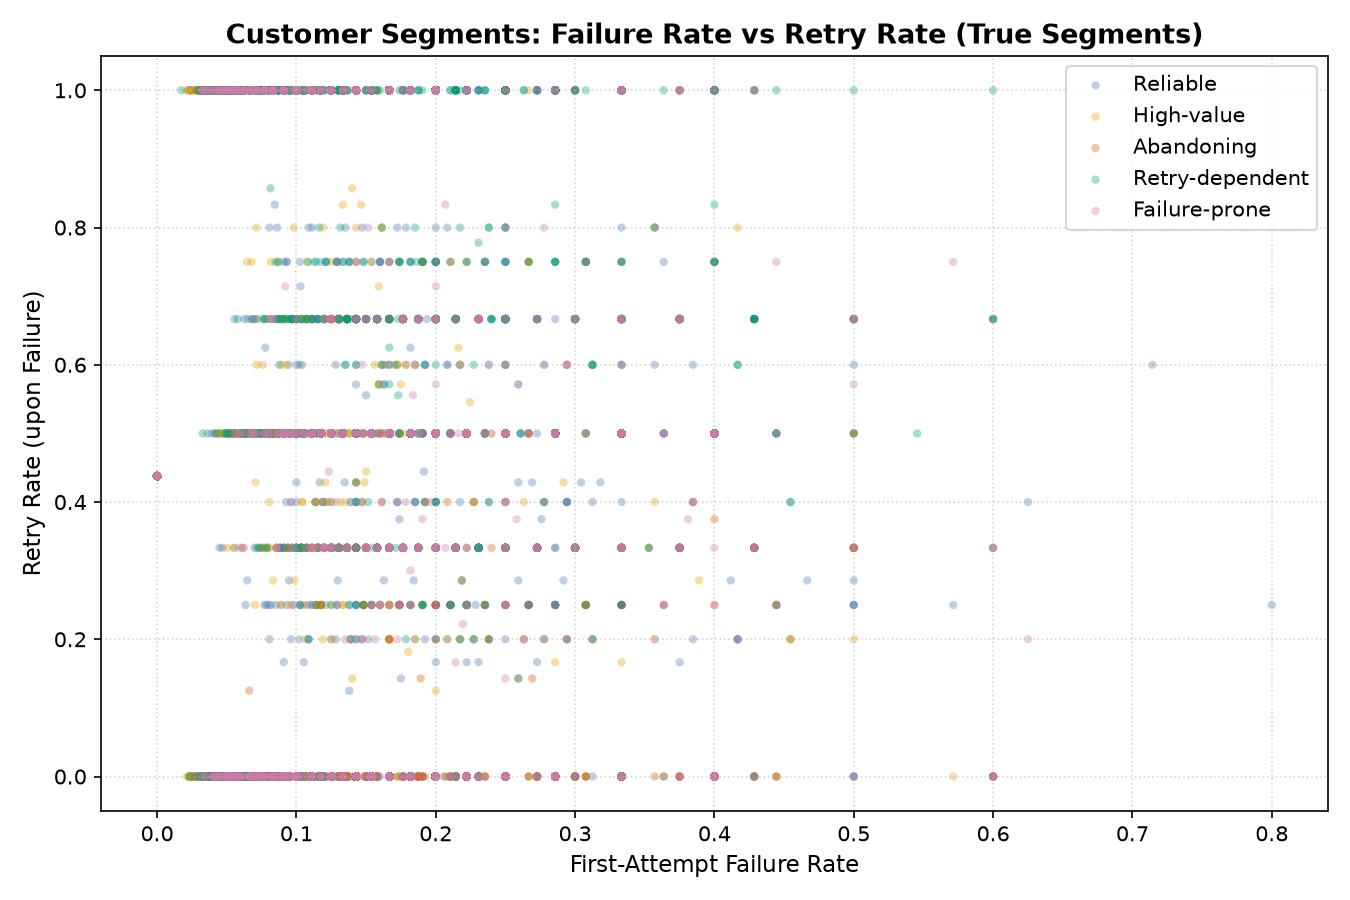

In [4]:
display(Image(filename=os.path.join(rep_dir, 'figures', 'p5_segments.png')))

# 5. Cohorts

First-attempt failure rate ranges from 7.88% (2026-09) to 9.32% (2026-04), and every cohort's 95% Wilson confidence interval overlaps the pooled rate of 9.21%. New cohorts show high activity in their signup month and subsequent months, with no pre-signup activity.

,cohort,customers,journeys,journeys_per_customer,failed_first,first_failure_pct,ci_low,ci_high,retry_rate_pct,recovery_all_pct,avg_amount
0,2026-04,1933,21040.0,10.88,1961.0,9.32,8.93,9.72,42.63,31.21,1260.0
1,2026-05,2011,17429.0,8.67,1590.0,9.12,8.70,9.56,43.84,31.32,1298.0
2,2026-06,1888,12855.0,6.81,1172.0,9.12,8.63,9.63,43.17,31.23,1223.0
3,2026-07,1908,9436.0,4.95,866.0,9.18,8.61,9.78,42.73,31.64,1314.0
4,2026-08,1728,5810.0,3.36,509.0,8.76,8.06,9.52,41.65,29.47,1340.0
5,2026-09,958,1827.0,1.91,144.0,7.88,6.73,9.21,39.58,22.92,1275.0
6,Before 2026-04,17896,211939.0,11.84,19563.0,9.23,9.11,9.35,43.85,31.03,1261.0


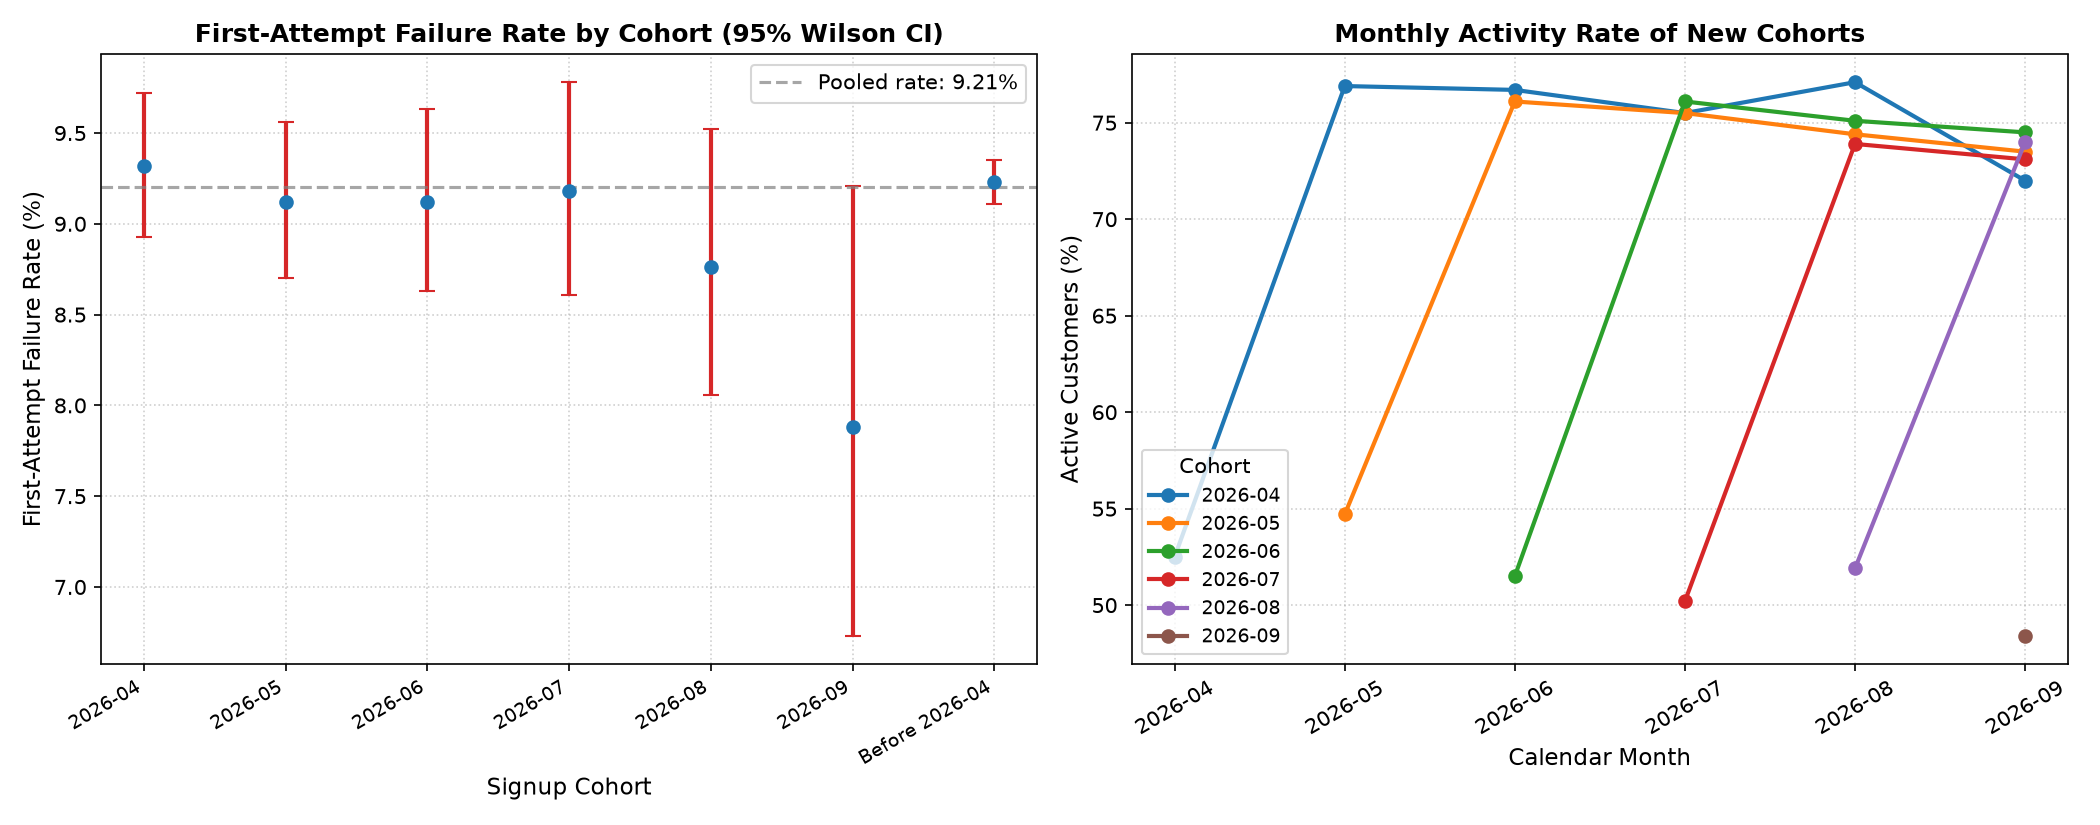

In [5]:
cohort_df = pd.read_csv(os.path.join(rep_dir, 'w3_cohort_table.csv'))
display(cohort_df)
display(Image(filename=os.path.join(rep_dir, 'figures', 'p5_cohorts.png')))

# 6. Limits

All analysis is on synthetic data with planted retry behaviour. Derived journeys misclassify some attempts (346 merged, about 676 split under w30b). Segmentation conclusions apply at this sample size only.

In [6]:
print('Phase 5 limits verified: derived journeys with w30b preserve ground-truth recovery within 1 percentage point.')

Phase 5 limits verified: derived journeys with w30b preserve ground-truth recovery within 1 percentage point.
